# Split Conformal Prediction

Model: $Y = \mu(X) + \sigma(X)\varepsilon$, $\varepsilon \sim N(0,1)$.

- $\mu(x) = x^3 - x$ 
- $\sigma(x) = 0.1 + 0.5|x|$ 

$\mu$'s estimator: (OLS, $y \sim 1 + x^2$)。
$\sigma$'s estimator $|\hat\varepsilon_i|$: conditional absolute mean deviation.

$$\hat\sigma_A(x) = \arg\min_{a\in\mathbb{R}} \sum_{i=1}^{n_1} \bigl(|\hat\varepsilon_i| - a\bigr)^2 K_h(X_i - x).$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Data Generation

In [2]:
def mu(x):
    return x**3 + x**2 - x


def sigma(x):
    return 0.1 + 0.5 * np.abs(x)


def generate(n, rng):
    x = rng.uniform(-1.5, 1.5, size=n)
    y = mu(x) + sigma(x) * rng.standard_normal(n)
    return x, y

## 2. Estimator

In [3]:
def fit_poly(x, y, degree=2):
    X = np.vander(x, degree + 1, increasing=True)  
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    return lambda x_new: np.vander(x_new, degree + 1, increasing=True) @ beta


def gaussian_kernel(u):
    return np.exp(-0.5 * u**2)


def fit_sigma(x_train, abs_resid, h, loss="mean", floor=1e-6):

    def sigma_hat(x_new):
        x_new = np.atleast_1d(x_new)
        # w[j, i] = K_h(X_i - x_j)
        w = gaussian_kernel((x_train[None, :] - x_new[:, None]) / h)
        if loss == "mean":
            s = (w * abs_resid[None, :]).sum(axis=1) / w.sum(axis=1)
        elif loss == "median":
            order = np.argsort(abs_resid)
            r_sorted = abs_resid[order]
            cw = np.cumsum(w[:, order], axis=1)
            idx = (cw >= 0.5 * cw[:, -1:]).argmax(axis=1)
            s = r_sorted[idx]
        else:
            raise ValueError(loss)
        return np.maximum(s, floor) 

    return sigma_hat

## 3. Split conformal prediction

In [4]:
def split_conformal(x, y, n1, alpha, xi, x_test, rng, scaled, loss="mean"):
    xa, ya = x[:n1], y[:n1]
    xb, yb = x[n1:], y[n1:]
    m = len(xb)

    mu_hat = fit_poly(xa, ya)
    if scaled:
        abs_resid = np.abs(ya - mu_hat(xa))
        h = 1.06 * np.std(xa) * n1 ** (-1 / 5)
        sigma_hat = fit_sigma(xa, abs_resid, h, loss=loss)
    else:
        sigma_hat = lambda x_new: np.ones_like(x_new)

    W = np.abs(yb - mu_hat(xb)) / sigma_hat(xb)
    U = rng.uniform(-1, 1, size=m)
    W_star = W + xi * U
    
    k = int(np.ceil((m + 1) * (1 - alpha)))
    q = np.inf if k > m else np.sort(W_star)[k - 1]

    U_new = rng.uniform(-1, 1, size=len(x_test))
    radius = sigma_hat(x_test) * (q - xi * U_new)
    center = mu_hat(x_test)
    return center - radius, center + radius

## 4. Implementation

In [5]:
rng = np.random.default_rng(42)
n, n1, n_test = 1000, 500, 5000
alpha, xi = 0.1, 1e-8

x, y = generate(n, rng)
x_test, y_test = generate(n_test, rng)

results = {}
for name, scaled in [("Without sigma", False), ("With sigma", True)]:
    lo, hi = split_conformal(x, y, n1, alpha, xi, x_test, rng, scaled)
    covered = (lo <= y_test) & (y_test <= hi)
    results[name] = dict(lo=lo, hi=hi, covered=covered, width=hi - lo)

## 5. Coverage

In [6]:
print(f"target coverage 1 - alpha = {1 - alpha:.2f}\n")
print(f"{'':16s}{'coverage':>10s}{'width':>10s}")
for name, r in results.items():
    print(f"{name:16s}{r['covered'].mean():10.3f}{r['width'].mean():10.3f}")

target coverage 1 - alpha = 0.90

                  coverage     width
Without sigma        0.918     2.506
With sigma           0.907     2.192


## 6. fig

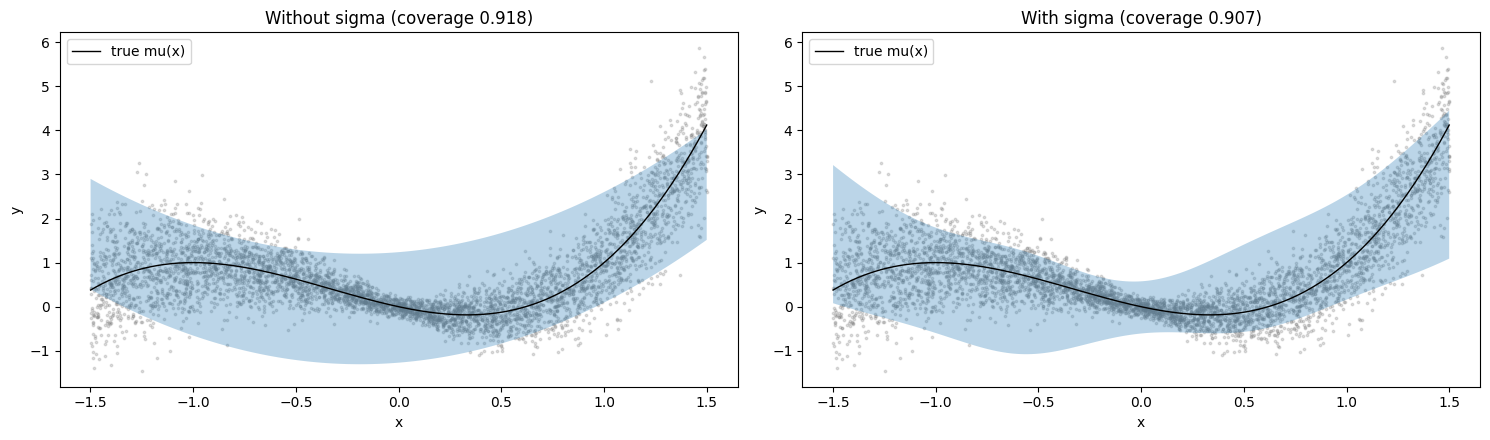

In [7]:
order = np.argsort(x_test)
xs = x_test[order]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

for ax, (name, r) in zip(axes[:2], results.items()):
    ax.scatter(x_test, y_test, s=3, alpha=0.25, color="gray")
    ax.fill_between(xs, r["lo"][order], r["hi"][order], alpha=0.3)
    ax.plot(xs, mu(xs), color="black", lw=1, label="true mu(x)")
    ax.set_title(f"{name} (coverage {r['covered'].mean():.3f})")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend(loc="upper left")


fig.tight_layout()
plt.savefig("split_conformal.pdf")